In [1]:
from pathlib import Path
import random
import shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
from ultralytics import YOLO

DEVICE = 0 if torch.cuda.is_available() else "cpu"
print("CUDA available:", torch.cuda.is_available())

CUDA available: True


## 1. Reproducibility and project paths

In [2]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

def find_project_root(start=None):
    start = (start or Path.cwd()).resolve()

    for candidate in [start, *start.parents]:
        if (candidate / "pyproject.toml").exists():
            return candidate

    raise FileNotFoundError(
        "Could not find the AutoVision project root."
    )

PROJECT_ROOT = find_project_root()

REPORT_DIR = (
    PROJECT_ROOT
    / "reports"
    / "damage_negative_training"
)

MODEL_DIR = (
    PROJECT_ROOT
    / "models"
    / "damage_negative_training"
)

OUTPUT_ROOT = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "cardd_with_undamaged_negatives"
)

INTERIM_DIR = (
    PROJECT_ROOT
    / "data"
    / "interim"
)

REPORT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Combined dataset:", OUTPUT_ROOT)

Project root: C:\Users\elesh\Academics\UTS\36127InnovationLab\Development\AutoVision_Model_Development
Combined dataset: C:\Users\elesh\Academics\UTS\36127InnovationLab\Development\AutoVision_Model_Development\data\processed\cardd_with_undamaged_negatives


## 2. Locating the prepared CarDD dataset

In [3]:
CARDD_CANDIDATES = [
    PROJECT_ROOT / "data" / "raw" / "cardd_kaggle" / "extracted",
    PROJECT_ROOT / "data" / "external" / "cardd_kaggle" / "extracted",
    Path(
        r"G:\.shortcut-targets-by-id\1OOvt005TduvEA8h6_snfuyQtbQAjo-3J"
        r"\capstone-vehicle-metadata\data\cardd_kaggle\extracted"
    ),
]

CARDD_ROOT = next(
    (
        p for p in CARDD_CANDIDATES
        if (p / "train" / "images").exists()
        and (p / "train" / "labels").exists()
        and (p / "val" / "images").exists()
        and (p / "val" / "labels").exists()
        and (p / "test" / "images").exists()
        and (p / "test" / "labels").exists()
    ),
    None,
)

print("CARDD_ROOT:", CARDD_ROOT)

if CARDD_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the prepared CarDD dataset."
    )

CARDD_ROOT: G:\.shortcut-targets-by-id\1OOvt005TduvEA8h6_snfuyQtbQAjo-3J\capstone-vehicle-metadata\data\cardd_kaggle\extracted


## 3. Setting the extracted undamaged-dataset folder

In [4]:
UNDAMAGED_ROOT = Path(
    r"C:\Users\elesh\Downloads\comprehensive-car-damage"
)

print("UNDAMAGED_ROOT:", UNDAMAGED_ROOT)

if not UNDAMAGED_ROOT.exists():
    raise FileNotFoundError(
        "UNDAMAGED_ROOT does not exist. "
        "Update the path in this cell."
    )

UNDAMAGED_ROOT: C:\Users\elesh\Downloads\comprehensive-car-damage


## 4. Finding and validating undamaged images

In [5]:
IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp",
}

clean_candidates = sorted([
    p
    for p in UNDAMAGED_ROOT.rglob("*")
    if p.is_file()
    and p.suffix.lower() in IMAGE_EXTENSIONS
])

print("Candidate undamaged images:", len(clean_candidates))

valid_clean_images = []
corrupt_rows = []

for i, image_path in enumerate(clean_candidates):
    try:
        with Image.open(image_path) as img:
            img.verify()

        valid_clean_images.append(image_path)

    except Exception as exc:
        corrupt_rows.append({
            "file_path": str(image_path),
            "error": str(exc),
        })

    if (i + 1) % 500 == 0:
        print(
            f"Checked {i + 1}/{len(clean_candidates)} images"
        )

print("Valid clean images:", len(valid_clean_images))
print("Corrupt/unreadable:", len(corrupt_rows))

pd.DataFrame(corrupt_rows).to_csv(
    REPORT_DIR / "undamaged_corrupt_images.csv",
    index=False,
)

Candidate undamaged images: 800
Checked 500/800 images
Valid clean images: 800
Corrupt/unreadable: 0


## 5. Splitting the undamaged dataset

In [6]:
MAX_CLEAN_IMAGES = 800

clean_images = valid_clean_images.copy()

rng = random.Random(SEED)
rng.shuffle(clean_images)

if (
    MAX_CLEAN_IMAGES is not None
    and len(clean_images) > MAX_CLEAN_IMAGES
):
    clean_images = clean_images[:MAX_CLEAN_IMAGES]

n_clean = len(clean_images)

# Final split:
# 600 train
# 80 validation
# 120 clean holdout
train_end = 600
val_end = 680

clean_train = clean_images[:train_end]
clean_val = clean_images[train_end:val_end]
clean_holdout = clean_images[val_end:]

print("Clean images used:", n_clean)
print("Clean train:", len(clean_train))
print("Clean val:", len(clean_val))
print("Clean holdout:", len(clean_holdout))

split_df = pd.DataFrame([
    {"split": "train", "count": len(clean_train)},
    {"split": "val", "count": len(clean_val)},
    {"split": "clean_holdout", "count": len(clean_holdout)},
])

display(split_df)

split_df.to_csv(
    REPORT_DIR / "undamaged_split_summary.csv",
    index=False,
)

Clean images used: 800
Clean train: 600
Clean val: 80
Clean holdout: 120


,split,count
0,train,600
1,val,80
2,clean_holdout,120


## 6. Previewing random undamaged vehicles

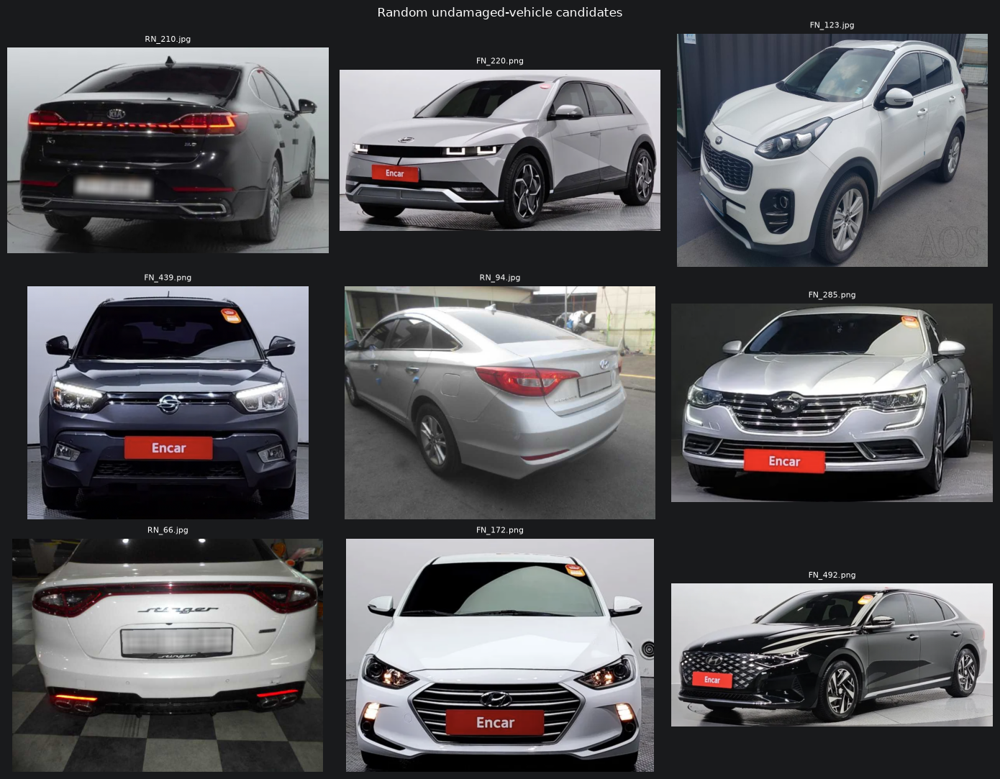

In [7]:
preview_count = min(9, len(clean_images))

if preview_count > 0:
    preview_images = rng.sample(
        clean_images,
        preview_count,
    )

    fig, axes = plt.subplots(
        3,
        3,
        figsize=(14, 11),
    )

    axes = axes.flatten()

    for ax in axes:
        ax.axis("off")

    for ax, image_path in zip(
        axes,
        preview_images,
    ):
        image = Image.open(
            image_path
        ).convert("RGB")

        ax.imshow(image)
        ax.set_title(
            image_path.name,
            fontsize=8,
        )
        ax.axis("off")

    plt.suptitle(
        "Random undamaged-vehicle candidates"
    )
    plt.tight_layout()
    plt.show()

## 7. Creating the new combined dataset

In [8]:
REBUILD_DATASET = True

if REBUILD_DATASET and OUTPUT_ROOT.exists():
    shutil.rmtree(OUTPUT_ROOT)

for split in ["train", "val"]:
    (
        OUTPUT_ROOT
        / split
        / "images"
    ).mkdir(
        parents=True,
        exist_ok=True,
    )

    (
        OUTPUT_ROOT
        / split
        / "labels"
    ).mkdir(
        parents=True,
        exist_ok=True,
    )

(
    OUTPUT_ROOT
    / "clean_holdout"
    / "images"
).mkdir(
    parents=True,
    exist_ok=True,
)

print("Combined dataset folders created.")

Combined dataset folders created.


## 8. Copying helpers

In [9]:
def safe_copy(source, destination):
    destination.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    shutil.copy2(
        source,
        destination,
    )


def copy_cardd_split(split):
    image_dir = (
        CARDD_ROOT
        / split
        / "images"
    )

    label_dir = (
        CARDD_ROOT
        / split
        / "labels"
    )

    copied = 0

    for image_path in sorted(
        image_dir.iterdir()
    ):
        if (
            image_path.suffix.lower()
            not in IMAGE_EXTENSIONS
        ):
            continue

        label_path = (
            label_dir
            / f"{image_path.stem}.txt"
        )

        if not label_path.exists():
            raise FileNotFoundError(
                f"Missing CarDD label: {label_path}"
            )

        safe_copy(
            image_path,
            OUTPUT_ROOT
            / split
            / "images"
            / f"cardd_{image_path.name}",
        )

        safe_copy(
            label_path,
            OUTPUT_ROOT
            / split
            / "labels"
            / f"cardd_{image_path.stem}.txt",
        )

        copied += 1

    return copied


def add_clean_negatives(images, split):
    copied = 0

    for i, image_path in enumerate(images):
        suffix = image_path.suffix.lower()
        stem = f"clean_{split}_{i:06d}"

        destination_image = (
            OUTPUT_ROOT
            / split
            / "images"
            / f"{stem}{suffix}"
        )

        destination_label = (
            OUTPUT_ROOT
            / split
            / "labels"
            / f"{stem}.txt"
        )

        safe_copy(
            image_path,
            destination_image,
        )

        # Empty label = no damage objects in this image.
        destination_label.write_text(
            "",
            encoding="utf-8",
        )

        copied += 1

    return copied

## 9. Copying CarDD train and validation

In [10]:
cardd_train_count = copy_cardd_split("train")
cardd_val_count = copy_cardd_split("val")

print("CarDD train copied:", cardd_train_count)
print("CarDD val copied:", cardd_val_count)

CarDD train copied: 2816
CarDD val copied: 810


## 10. Adding clean negative images

In [11]:
clean_train_count = add_clean_negatives(
    clean_train,
    "train",
)

clean_val_count = add_clean_negatives(
    clean_val,
    "val",
)

print("Clean train negatives:", clean_train_count)
print("Clean val negatives:", clean_val_count)

Clean train negatives: 600
Clean val negatives: 80


## 11. Copying the clean holdout separately

In [12]:
holdout_rows = []

for i, image_path in enumerate(clean_holdout):
    suffix = image_path.suffix.lower()

    destination = (
        OUTPUT_ROOT
        / "clean_holdout"
        / "images"
        / f"clean_holdout_{i:06d}{suffix}"
    )

    safe_copy(
        image_path,
        destination,
    )

    holdout_rows.append({
        "source_path": str(image_path),
        "holdout_path": str(destination),
    })

holdout_manifest_df = pd.DataFrame(
    holdout_rows
)

holdout_manifest_df.to_csv(
    REPORT_DIR / "clean_holdout_manifest.csv",
    index=False,
)

print(
    "Clean holdout copied:",
    len(holdout_manifest_df),
)

Clean holdout copied: 120


## 12. Verifying the combined dataset

In [13]:
def count_images(folder):
    return len([
        p
        for p in folder.iterdir()
        if p.suffix.lower() in IMAGE_EXTENSIONS
    ])


summary_rows = []

for split in ["train", "val"]:
    image_dir = (
        OUTPUT_ROOT
        / split
        / "images"
    )

    label_dir = (
        OUTPUT_ROOT
        / split
        / "labels"
    )

    image_count = count_images(image_dir)

    label_paths = list(
        label_dir.glob("*.txt")
    )

    empty_count = sum(
        1
        for p in label_paths
        if p.read_text(
            encoding="utf-8"
        ).strip() == ""
    )

    summary_rows.append({
        "split": split,
        "images": image_count,
        "labels": len(label_paths),
        "empty_negative_labels": empty_count,
        "damage_label_files": (
            len(label_paths)
            - empty_count
        ),
    })

dataset_summary_df = pd.DataFrame(
    summary_rows
)

display(dataset_summary_df)

dataset_summary_df.to_csv(
    REPORT_DIR / "combined_dataset_summary.csv",
    index=False,
)

assert (
    dataset_summary_df["images"]
    == dataset_summary_df["labels"]
).all(), (
    "Each combined image must have a matching .txt label."
)

,split,images,labels,empty_negative_labels,damage_label_files
0,train,3416,3416,600,2816
1,val,890,890,80,810


## 13. Creating combined YOLO YAML

In [14]:
CLASS_NAMES = [
    "dent",
    "scratch",
    "crack",
    "glass shatter",
    "lamp broken",
    "tire flat",
]

COMBINED_YAML = (
    INTERIM_DIR
    / "cardd_with_undamaged_negatives.yaml"
)

yaml_lines = [
    f'train: "{(OUTPUT_ROOT / "train" / "images").as_posix()}"',
    f'val: "{(OUTPUT_ROOT / "val" / "images").as_posix()}"',
    f'test: "{(CARDD_ROOT / "test" / "images").as_posix()}"',
    "names:",
]

for class_id, class_name in enumerate(CLASS_NAMES):
    yaml_lines.append(
        f"  {class_id}: {class_name}"
    )

COMBINED_YAML.write_text(
    "\n".join(yaml_lines) + "\n",
    encoding="utf-8",
)

print(
    COMBINED_YAML.read_text(
        encoding="utf-8"
    )
)

print("Saved:", COMBINED_YAML)

train: "C:/Users/elesh/Academics/UTS/36127InnovationLab/Development/AutoVision_Model_Development/data/processed/cardd_with_undamaged_negatives/train/images"
val: "C:/Users/elesh/Academics/UTS/36127InnovationLab/Development/AutoVision_Model_Development/data/processed/cardd_with_undamaged_negatives/val/images"
test: "G:/.shortcut-targets-by-id/1OOvt005TduvEA8h6_snfuyQtbQAjo-3J/capstone-vehicle-metadata/data/cardd_kaggle/extracted/test/images"
names:
  0: dent
  1: scratch
  2: crack
  3: glass shatter
  4: lamp broken
  5: tire flat

Saved: C:\Users\elesh\Academics\UTS\36127InnovationLab\Development\AutoVision_Model_Development\data\interim\cardd_with_undamaged_negatives.yaml


## 14. Selecting the initialization checkpoint

In [15]:
START_FROM_TUNED = True

TUNED_CHECKPOINT = (
    PROJECT_ROOT
    / "models"
    / "damage_hyperparameter_tuning"
    / "640_longer"
    / "weights"
    / "best.pt"
)

PRETRAINED_WEIGHT = (
    PROJECT_ROOT
    / "notebooks"
    / "yolo11s.pt"
)

INITIAL_WEIGHT = (
    TUNED_CHECKPOINT
    if START_FROM_TUNED
    else PRETRAINED_WEIGHT
)

print("Initial weight:", INITIAL_WEIGHT)

if not INITIAL_WEIGHT.exists():
    raise FileNotFoundError(
        f"Missing weights: {INITIAL_WEIGHT}"
    )

Initial weight: C:\Users\elesh\Academics\UTS\36127InnovationLab\Development\AutoVision_Model_Development\models\damage_hyperparameter_tuning\640_longer\weights\best.pt


## 15. Training YOLO11s with CarDD and clean negatives

In [22]:
TRAIN_IMGSZ = 640
TRAIN_BATCH = 8
TRAIN_EPOCHS = 20
PATIENCE = 5

if torch.cuda.is_available():
    torch.cuda.empty_cache()

model = YOLO(
    str(INITIAL_WEIGHT)
)

train_result = model.train(
    data=str(COMBINED_YAML),
    project=str(MODEL_DIR),

    # Keep this as a separate experiment
    name="yolo11s_cardd_plus_clean_lr1e4",
    exist_ok=True,

    imgsz=TRAIN_IMGSZ,
    batch=TRAIN_BATCH,
    epochs=TRAIN_EPOCHS,
    patience=PATIENCE,

    # Gentler fine-tuning
    optimizer="AdamW",
    lr0=0.0001,

    workers=0,
    device=DEVICE,
    seed=SEED,
    deterministic=True,
    amp=True,
    cache=False,
    plots=True,
    verbose=True,
)

RUN_DIR = Path(
    train_result.save_dir
)

BEST_CHECKPOINT = (
    RUN_DIR
    / "weights"
    / "best.pt"
)

print(
    "Best checkpoint:",
    BEST_CHECKPOINT
)

New https://pypi.org/project/ultralytics/8.4.173 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.171  Python-3.11.4 torch-2.14.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8123MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\elesh\Academics\UTS\36127InnovationLab\Development\AutoVision_Model_Development\data\interim\cardd_with_undamaged_negatives.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou

## 16. Evaluating on the original untouched CarDD test split

In [23]:
final_model = YOLO(
    str(BEST_CHECKPOINT)
)

cardd_test_metrics = final_model.val(
    data=str(COMBINED_YAML),
    split="test",
    imgsz=TRAIN_IMGSZ,
    batch=TRAIN_BATCH,
    workers=0,
    device=DEVICE,
    plots=True,
    verbose=False,
)

box = cardd_test_metrics.box

cardd_test_summary = {
    "precision": float(box.mp),
    "recall": float(box.mr),
    "map50": float(box.map50),
    "map50_95": float(box.map),
    "inference_ms": float(
        cardd_test_metrics.speed.get(
            "inference",
            np.nan,
        )
    ),
}

print("CarDD test:")
print(cardd_test_summary)

pd.DataFrame([
    cardd_test_summary
]).to_csv(
    REPORT_DIR
    / "cardd_test_result_after_negative_training.csv",
    index=False,
)

Ultralytics 8.4.171  Python-3.11.4 torch-2.14.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8123MiB)
YOLO11s summary (fused): 100 layers, 9,415,122 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access  (ping: 1.30.3 ms, read: 55.210.3 MB/s, size: 829.6 KB)
val: Scanning G:\.shortcut-targets-by-id\1OOvt005TduvEA8h6_snfuyQtbQAjo-3J\capstone-vehicle-metadata\data\cardd_kaggle\extracted\test\labels... 374 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 374/374 154.2it/s 2.4s0.1s
WARNING val: Failed to save cache to G:\.shortcut-targets-by-id\1OOvt005TduvEA8h6_snfuyQtbQAjo-3J\capstone-vehicle-metadata\data\cardd_kaggle\extracted\test\labels.cache: [Errno 13] Permission denied: 'G:\\.shortcut-targets-by-id\\1OOvt005TduvEA8h6_snfuyQtbQAjo-3J\\capstone-vehicle-metadata\\data\\cardd_kaggle\\extracted\\test\\labels.cache'
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 47/47 3.3it/s 14.3s0.3s
                   all     

## 17. CarDD test per-class metrics

In [24]:
p = np.asarray(
    getattr(box, "p", [])
)

r = np.asarray(
    getattr(box, "r", [])
)

ap50 = np.asarray(
    getattr(box, "ap50", [])
)

maps = np.asarray(
    getattr(box, "maps", [])
)

rows = []

for i, class_name in enumerate(CLASS_NAMES):
    rows.append({
        "class_id": i,
        "damage_class": class_name,
        "precision": (
            float(p[i])
            if i < len(p)
            else np.nan
        ),
        "recall": (
            float(r[i])
            if i < len(r)
            else np.nan
        ),
        "ap50": (
            float(ap50[i])
            if i < len(ap50)
            else np.nan
        ),
        "ap50_95": (
            float(maps[i])
            if i < len(maps)
            else np.nan
        ),
    })

per_class_df = pd.DataFrame(rows)

display(per_class_df)

per_class_df.to_csv(
    REPORT_DIR
    / "cardd_test_per_class_after_negative_training.csv",
    index=False,
)

,class_id,damage_class,precision,recall,ap50,ap50_95
0,0,dent,0.739069,0.552089,0.656620,0.387914
1,1,scratch,0.666494,0.527278,0.618291,0.341013
2,2,crack,0.534539,0.400000,0.441937,0.247668
3,3,glass shatter,0.913744,0.985915,0.989829,0.916623
4,4,lamp broken,0.745244,0.782609,0.851371,0.710307
5,5,tire flat,0.905241,0.875000,0.894513,0.870587


## 18. Evaluating the clean holdout

In [25]:
CONF_THRESHOLDS = [
    0.25,
    0.35,
    0.50,
]

holdout_dir = (
    OUTPUT_ROOT
    / "clean_holdout"
    / "images"
)

holdout_images = sorted([
    p
    for p in holdout_dir.iterdir()
    if p.suffix.lower() in IMAGE_EXTENSIONS
])

print("Clean holdout images:", len(holdout_images))

summary_counts = {
    threshold: {
        "images_with_prediction": 0,
        "total_predictions": 0,
    }
    for threshold in CONF_THRESHOLDS
}

prediction_rows = []

for i, image_path in enumerate(holdout_images):
    result = final_model.predict(
        source=str(image_path),
        imgsz=TRAIN_IMGSZ,
        conf=min(CONF_THRESHOLDS),
        device=DEVICE,
        verbose=False,
    )[0]

    boxes = result.boxes

    if boxes is not None and len(boxes) > 0:
        cls_ids = (
            boxes.cls
            .cpu()
            .numpy()
            .astype(int)
        )

        confidences = (
            boxes.conf
            .cpu()
            .numpy()
        )

        for threshold in CONF_THRESHOLDS:
            keep = confidences >= threshold
            count = int(keep.sum())

            if count > 0:
                summary_counts[
                    threshold
                ][
                    "images_with_prediction"
                ] += 1

                summary_counts[
                    threshold
                ][
                    "total_predictions"
                ] += count

                for cls_id, confidence in zip(
                    cls_ids[keep],
                    confidences[keep],
                ):
                    prediction_rows.append({
                        "confidence_threshold": threshold,
                        "image_path": str(image_path),
                        "predicted_damage": final_model.names[
                            int(cls_id)
                        ],
                        "prediction_confidence": float(confidence),
                    })

    del result

    if (
        torch.cuda.is_available()
        and (i + 1) % 50 == 0
    ):
        torch.cuda.empty_cache()

    if (i + 1) % 50 == 0:
        print(
            f"Processed {i + 1}/{len(holdout_images)}"
        )

clean_summary_rows = []

for threshold in CONF_THRESHOLDS:
    flagged = (
        summary_counts[
            threshold
        ][
            "images_with_prediction"
        ]
    )

    total_predictions = (
        summary_counts[
            threshold
        ][
            "total_predictions"
        ]
    )

    clean_summary_rows.append({
        "confidence_threshold": threshold,
        "clean_images_evaluated": len(holdout_images),
        "clean_images_flagged": flagged,
        "false_positive_image_rate": (
            flagged / len(holdout_images)
            if len(holdout_images) > 0
            else np.nan
        ),
        "total_false_positive_boxes": total_predictions,
    })

clean_holdout_summary_df = pd.DataFrame(
    clean_summary_rows
)

clean_holdout_predictions_df = pd.DataFrame(
    prediction_rows
)

display(clean_holdout_summary_df)

clean_holdout_summary_df.to_csv(
    REPORT_DIR
    / "clean_holdout_false_positive_summary.csv",
    index=False,
)

clean_holdout_predictions_df.to_csv(
    REPORT_DIR
    / "clean_holdout_false_positive_predictions.csv",
    index=False,
)

Clean holdout images: 120
Processed 50/120
Processed 100/120


,confidence_threshold,clean_images_evaluated,clean_images_flagged,false_positive_image_rate,total_false_positive_boxes
0,0.25,120,10,0.083333,12
1,0.35,120,7,0.058333,8
2,0.50,120,2,0.016667,2


## 19. Evaluating the old 640_longer model on the same holdout images

In [21]:
OLD_CHECKPOINT = (
    PROJECT_ROOT
    / "models"
    / "damage_hyperparameter_tuning"
    / "640_longer"
    / "weights"
    / "best.pt"
)

print("Old checkpoint:", OLD_CHECKPOINT)
print("Same clean holdout images:", len(holdout_images))

if not OLD_CHECKPOINT.exists():
    raise FileNotFoundError(
        f"Old checkpoint not found: {OLD_CHECKPOINT}"
    )

old_model = YOLO(
    str(OLD_CHECKPOINT)
)

CONF_THRESHOLDS = [
    0.25,
    0.35,
    0.50,
]

old_summary_counts = {
    threshold: {
        "images_with_prediction": 0,
        "total_predictions": 0,
    }
    for threshold in CONF_THRESHOLDS
}

old_prediction_rows = []

for i, image_path in enumerate(holdout_images):

    # Predict once at the lowest threshold
    result = old_model.predict(
        source=str(image_path),
        imgsz=640,
        conf=min(CONF_THRESHOLDS),
        device=DEVICE,
        verbose=False,
    )[0]

    boxes = result.boxes

    if boxes is not None and len(boxes) > 0:

        cls_ids = (
            boxes.cls
            .cpu()
            .numpy()
            .astype(int)
        )

        confidences = (
            boxes.conf
            .cpu()
            .numpy()
        )

        for threshold in CONF_THRESHOLDS:

            keep = confidences >= threshold
            count = int(keep.sum())

            if count > 0:

                old_summary_counts[
                    threshold
                ]["images_with_prediction"] += 1

                old_summary_counts[
                    threshold
                ]["total_predictions"] += count

                for cls_id, confidence in zip(
                    cls_ids[keep],
                    confidences[keep],
                ):
                    old_prediction_rows.append({
                        "confidence_threshold": threshold,
                        "image_path": str(image_path),
                        "predicted_damage": old_model.names[
                            int(cls_id)
                        ],
                        "prediction_confidence": float(confidence),
                    })

    del result

    if (
        torch.cuda.is_available()
        and (i + 1) % 50 == 0
    ):
        torch.cuda.empty_cache()

    if (i + 1) % 50 == 0:
        print(
            f"Processed {i + 1}/{len(holdout_images)}"
        )


old_clean_summary_rows = []

for threshold in CONF_THRESHOLDS:

    flagged = (
        old_summary_counts[
            threshold
        ]["images_with_prediction"]
    )

    total_predictions = (
        old_summary_counts[
            threshold
        ]["total_predictions"]
    )

    old_clean_summary_rows.append({
        "confidence_threshold": threshold,
        "clean_images_evaluated": len(holdout_images),
        "clean_images_flagged": flagged,
        "false_positive_image_rate": (
            flagged / len(holdout_images)
        ),
        "total_false_positive_boxes": total_predictions,
    })


old_clean_holdout_summary_df = pd.DataFrame(
    old_clean_summary_rows
)

display(
    old_clean_holdout_summary_df
)

Old checkpoint: C:\Users\elesh\Academics\UTS\36127InnovationLab\Development\AutoVision_Model_Development\models\damage_hyperparameter_tuning\640_longer\weights\best.pt
Same clean holdout images: 120
Processed 50/120
Processed 100/120


,confidence_threshold,clean_images_evaluated,clean_images_flagged,false_positive_image_rate,total_false_positive_boxes
0,0.25,120,65,0.541667,113
1,0.35,120,54,0.450000,76
2,0.50,120,37,0.308333,44


## 20. Displaying highest-confidence clean-holdout false positives

False-positive images to inspect: 10


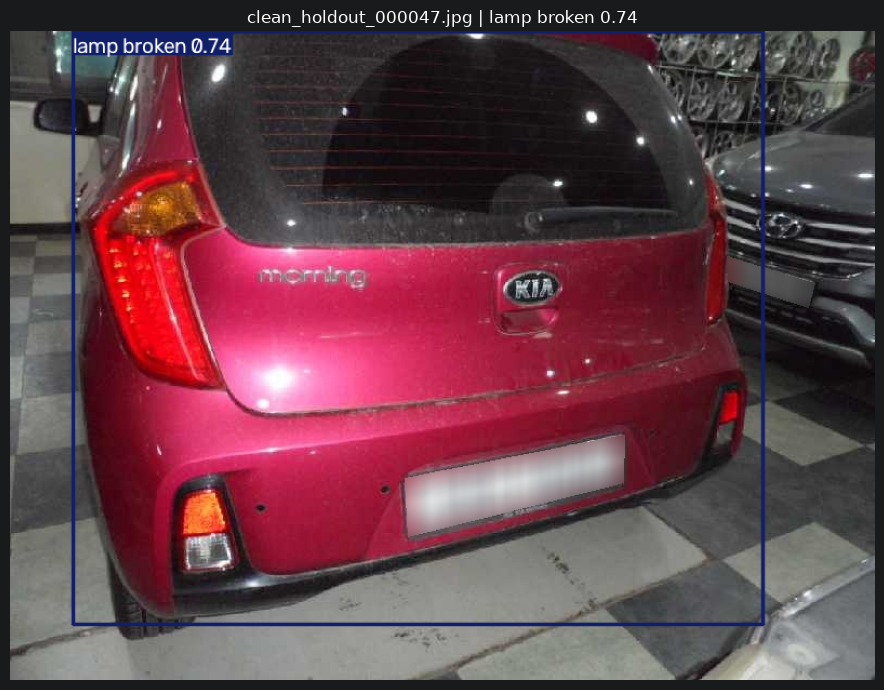

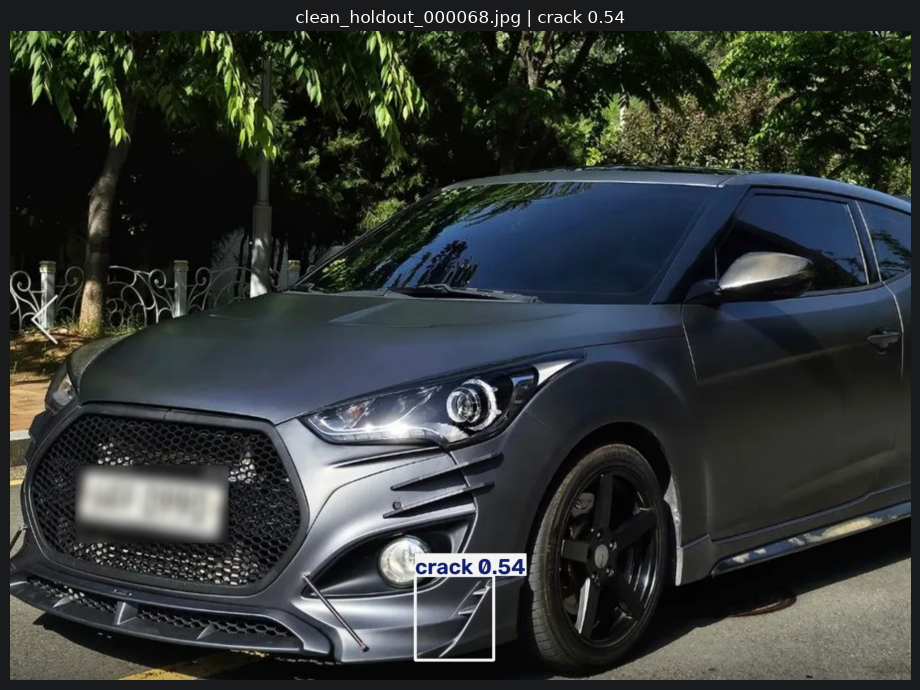

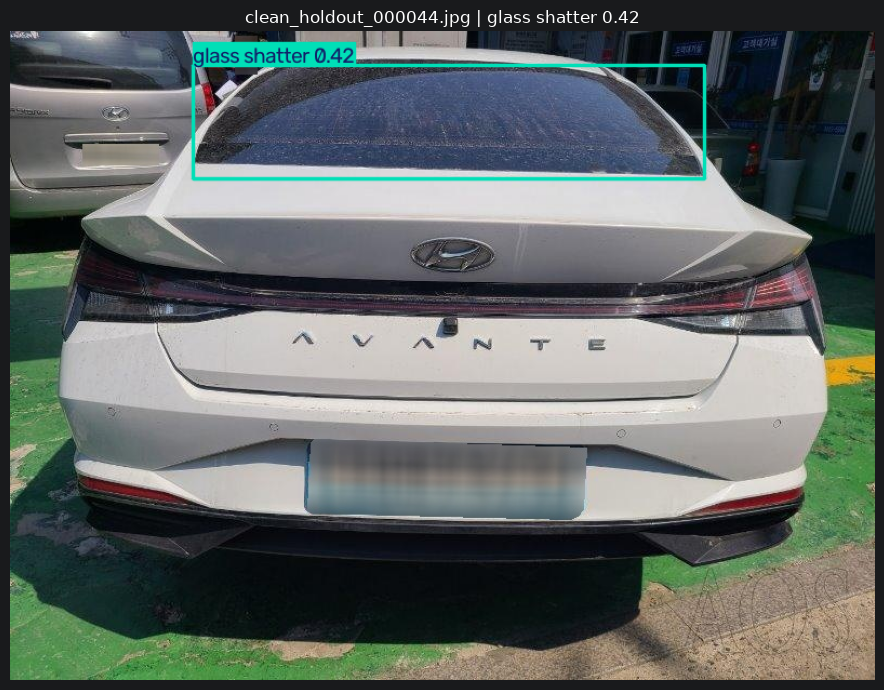

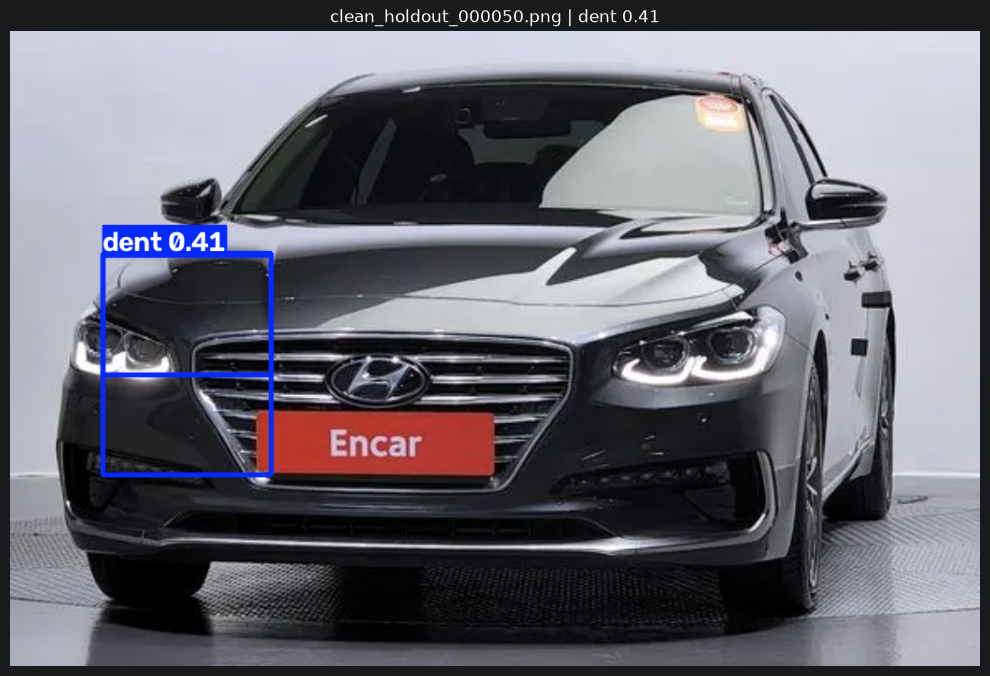

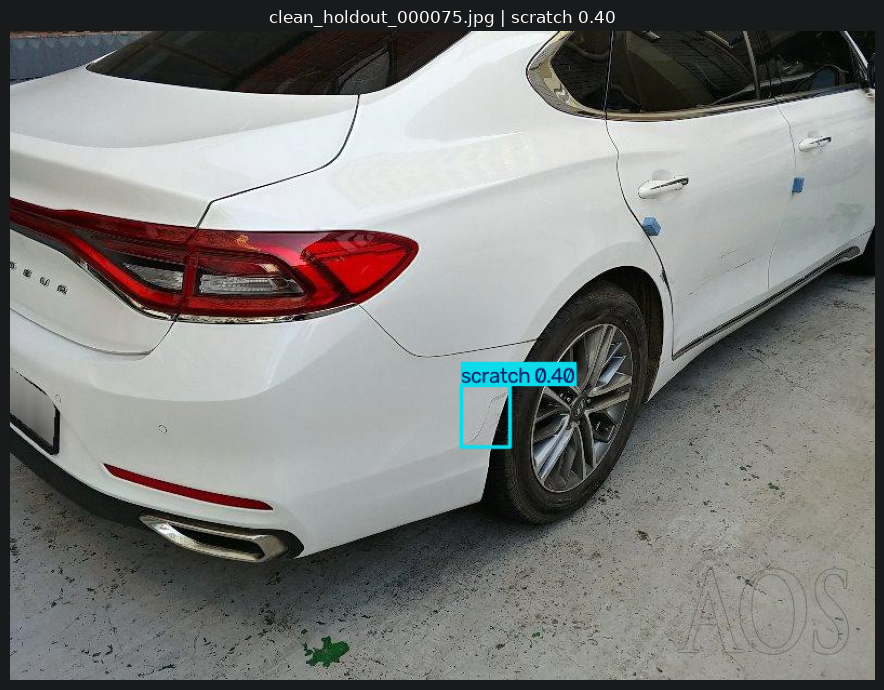

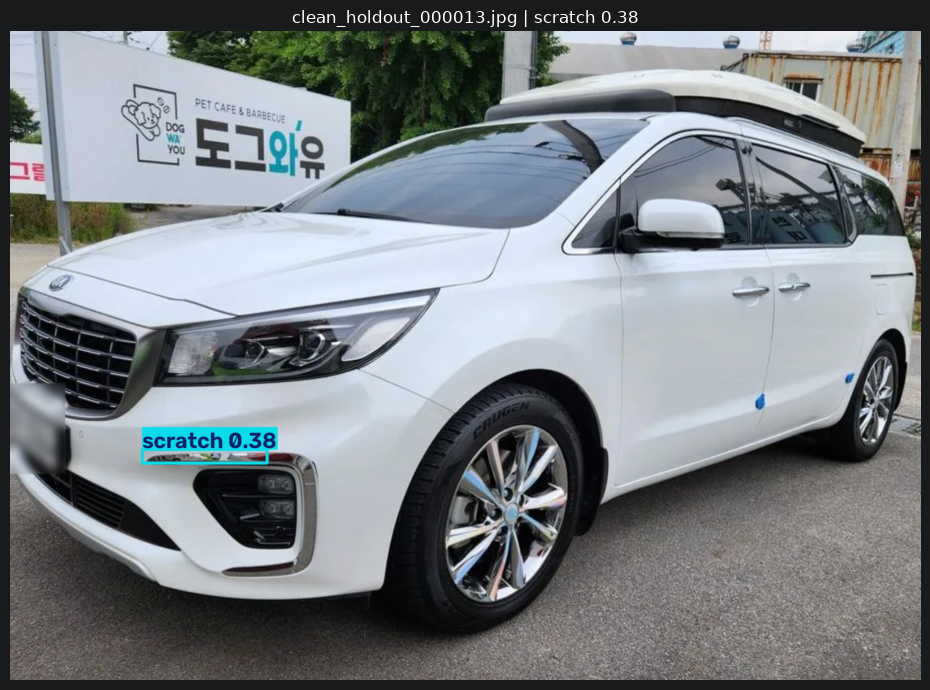

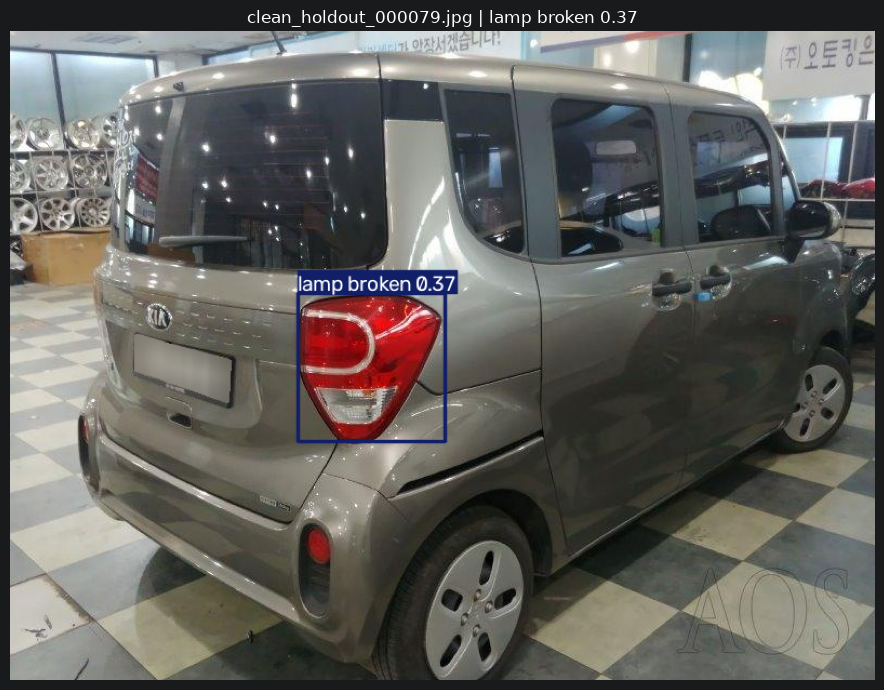

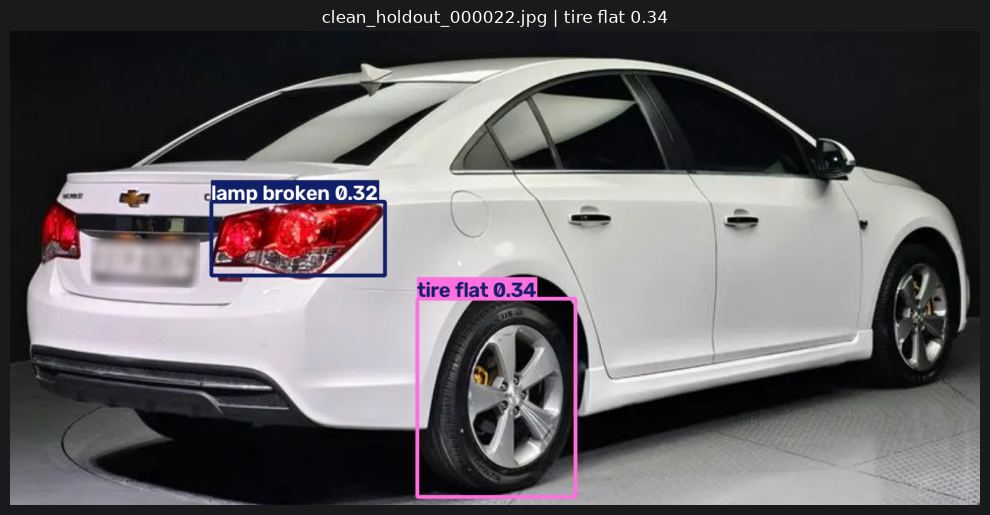

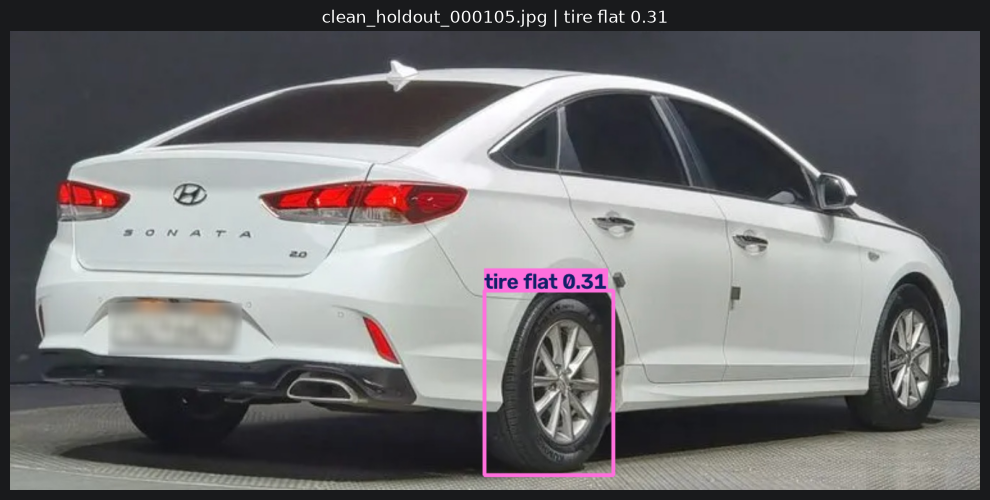

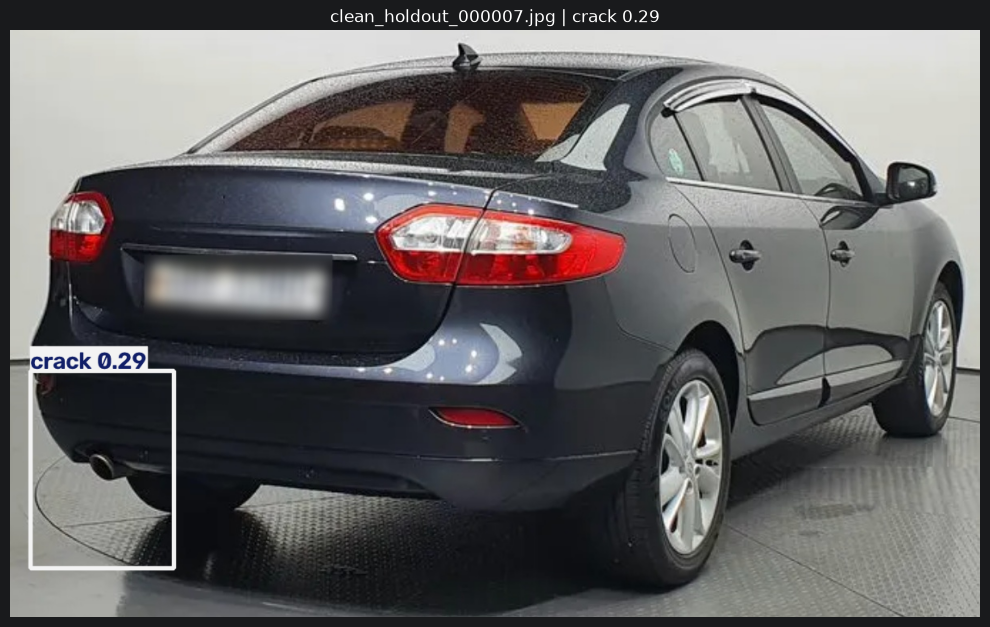

In [26]:
if len(clean_holdout_predictions_df) == 0:
    print(
        "No clean-holdout false positives were produced."
    )

else:
    review_df = (
        clean_holdout_predictions_df[
            clean_holdout_predictions_df[
                "confidence_threshold"
            ] == 0.25
        ]
        .sort_values(
            "prediction_confidence",
            ascending=False,
        )
        .drop_duplicates("image_path")
        .head(24)
    )

    print(
        "False-positive images to inspect:",
        len(review_df),
    )

    for _, row in review_df.iterrows():
        image_path = row["image_path"]

        result = final_model.predict(
            source=image_path,
            imgsz=TRAIN_IMGSZ,
            conf=0.25,
            device=DEVICE,
            verbose=False,
        )[0]

        plotted = (
            result.plot()
            [:, :, ::-1]
        )

        plt.figure(
            figsize=(10, 7)
        )

        plt.imshow(plotted)

        plt.title(
            f"{Path(image_path).name} | "
            f"{row['predicted_damage']} "
            f"{row['prediction_confidence']:.2f}"
        )

        plt.axis("off")
        plt.tight_layout()
        plt.show()